# 02 – Feature selection : quelles variables influencent chaque cible Y ?

**Objectif :** pour chaque variable cible **Y** du Bitcoin, trouver les variables explicatives **X** qui ont une vraie relation avec elle, puis construire **un modèle par cible** qui prédit Y **à la bougie suivante** (8 h plus tard).

| Cible Y | Définition (au futur) | Référence naïve |
|---|---|---|
| `rendement` | rendement log de la bougie t+1 | 0 (pas de prévision) |
| `volatilite` | volatilité réalisée de la journée suivante (bougies t+1, t+2, t+3) | volatilité des dernières 24 h |
| `close` | log du prix de clôture de la bougie t+1 | prix actuel |
| `MACD` | MACD normalisé (MACD / prix) de la bougie t+1 | MACD actuel |

**Règle anti-triche (pas de look-ahead) :** les X sont connues à la clôture de la bougie t, les Y sont au futur. Le MACD et le RSI sont calculés à partir du prix : les relier au prix *du même instant* donnerait une relation parfaite mais sans intérêt.

**Pourquoi une volatilité « de la journée suivante » ?** La volatilité glissante sur 60 bougies change à peine d'une bougie à l'autre : la prédire à t+1 serait trivial. La volatilité réalisée sur les 24 h suivantes est une vraie cible de prévision.

**4 méthodes de sélection**, calculées sur le train uniquement :
1. **Corrélation de Spearman** : relation monotone, linéaire ou non ;
2. **Information mutuelle** : n'importe quelle dépendance, même non monotone ;
3. **Lasso** (régression L1) : garde les variables utiles *ensemble*, met les autres à 0 ;
4. **Importance par permutation d'une forêt aléatoire** : de combien l'erreur augmente quand on mélange la variable.

**Règle de vote :** une variable est **retenue** si elle est dans le top 5 d'au moins 3 méthodes sur 4.

## 1. Paramètres et données

In [1]:
import sys, json, warnings
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from fonctions import *

warnings.filterwarnings("ignore")

TOP_K, VOTES_MIN = 5, 3        # top 5 de chaque méthode, retenue si >= 3 votes sur 4
VAL_FRAC = 0.2                 # dernière partie du train réservée à la validation (choix du modèle)
RF = dict(n_estimators=200, max_depth=6, min_samples_leaf=50, n_jobs=-1, random_state=0)

df = garder_jours_complets(pd.read_csv("../data/btcusdt_8h.csv", index_col=0, parse_dates=True))
feat = construire_features(df)
X_all = construire_candidates(df, feat)
Y_all = construire_cibles(df, feat)
data = garder_jours_complets(X_all.join(Y_all.add_prefix("Y_")).dropna())
X_all, Y_all = data[X_all.columns], data[[c for c in data.columns if c.startswith("Y_")]]
Y_all.columns = [c[2:] for c in Y_all.columns]

# même date de début du test que le notebook 01 (et donc que le HMM)
debut_test = pd.read_csv("../data/btcusdt_X_test.csv", index_col=0, parse_dates=True).index[0]
train = data.index < debut_test
train &= data.index < data.index[train][-PAR_JOUR]   # on retire le dernier jour du train : sa cible utilise le test
test = data.index >= debut_test
print(f"{len(data)} lignes ({len(data) // 3} jours) | train : {train.sum()} | test : {test.sum()} (à partir du {debut_test.date()})")

10020 lignes (3340 jours) | train : 7011 | test : 3006 (à partir du 2024-02-02)


> **Interprétation :**
>
> Après le calcul des variables et la suppression des lignes incomplètes, il reste **10 020 lignes (3 340 jours)**.
> Le test commence le **2 février 2024**, comme dans le notebook 01 : toutes les parties du projet sont évaluées sur la même période.

## 2. Les variables candidates X
15 variables connues à l'instant t : les indicateurs du notebook 01, les rendements passés (lags, 24 h, 7 jours), deux volatilités courtes, la session de la bougie (00h, 08h ou 16h) et le niveau de prix `log_close`.

`log_close` n'est proposé **que pour la cible `close`**. Pour les autres cibles, une variable non stationnaire (le prix monte sur 9 ans) créerait des relations fausses.

In [2]:
X_all[train].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
rendement,7011.0,0.0003,0.0222,-0.2449,-0.0077,0.0003,0.0085,0.1961
volatilite,7011.0,0.0199,0.0099,0.0041,0.0135,0.0179,0.0232,0.0576
RSI,7011.0,51.4568,8.9106,20.1020,45.4896,50.3947,57.1833,81.3347
MACD_norm,7011.0,0.0007,0.0477,-0.2187,-0.0229,0.0013,0.0323,0.1439
histo_norm,7011.0,0.0001,0.0144,-0.0875,-0.0067,0.0007,0.0089,0.0459
amplitude,7011.0,0.0308,0.0264,0.0015,0.0149,0.0238,0.0379,0.3792
vol_rel,7011.0,-0.0865,0.5149,-2.6287,-0.3994,-0.1002,0.2118,2.4597
rend_lag1,7011.0,0.0003,0.0222,-0.2449,-0.0077,0.0003,0.0086,0.1961
rend_lag2,7011.0,0.0003,0.0222,-0.2449,-0.0077,0.0003,0.0086,0.1961
rend_1j,7011.0,0.0010,0.0392,-0.5026,-0.0146,0.0009,0.0175,0.2394


> **Interprétation :**
>
> Ce tableau décrit les 15 variables candidates sur le train. Exemples :
> - `rend_1sem` varie beaucoup plus que `rendement` (écart-type 10 % contre 2 %), car il additionne une semaine de rendements ;
> - `session_08h` et `session_16h` valent 1/3 en moyenne : il y a bien autant de bougies de chaque session.

## 3. Vue d'ensemble : corrélation de Spearman entre X (à t) et Y (au futur)
Sur le train. Les cases foncées montrent les relations les plus fortes.

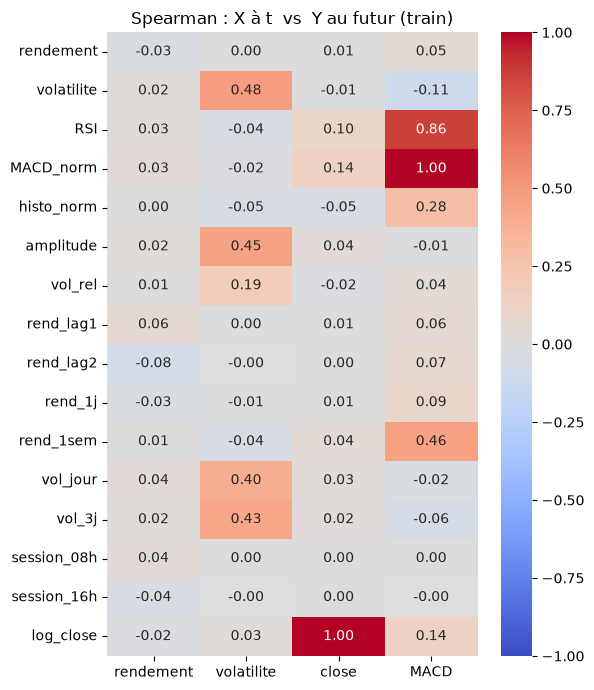

In [3]:
rho = pd.DataFrame({y: [spearmanr(X_all.loc[train, x], Y_all.loc[train, y])[0] for x in X_all.columns]
                    for y in Y_all.columns}, index=X_all.columns)
plt.figure(figsize=(6, 7))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman : X à t  vs  Y au futur (train)")
plt.tight_layout(); plt.savefig("../results/selection_spearman.png", dpi=150); plt.show()

> **Interprétation :**
>
> Chaque case donne la force du lien entre une variable X (aujourd'hui) et une cible Y (au futur). 0 = aucun lien, 1 = lien parfait.
> - **Rendement :** toute la colonne est presque à 0 (au plus 0,08). Aucune variable n'annonce vraiment le rendement suivant.
> - **Volatilité :** liens nets avec la volatilité (0,48), l'amplitude (0,45), la volatilité sur 3 jours (0,43) et celle du jour (0,40). Quand le marché est agité aujourd'hui, il le reste souvent demain.
> - **Close :** seul le prix actuel (`log_close`) compte, avec un lien de 1,00. Le meilleur indice du prix futur est le prix actuel.
> - **MACD :** liens très forts avec le MACD actuel (1,00) et le RSI (0,86). Le MACD change lentement.

## 4. Les 4 méthodes de sélection
La fonction `selectionner` calcule les 4 scores pour une cible, sur la partie *apprentissage* du train. L'importance par permutation est mesurée sur la partie *validation* du train : une variable qui n'aide que sur les données d'apprentissage (sur-apprentissage) n'est pas récompensée.

In [4]:
def candidates_pour(cible):
    return [c for c in X_all.columns if c != "log_close" or cible == "close"]

def selectionner(cible):
    cols = candidates_pour(cible)
    X, y = X_all.loc[train, cols], Y_all.loc[train, cible]
    k = int(len(X) // PAR_JOUR * (1 - VAL_FRAC)) * PAR_JOUR          # coupure sur des jours entiers
    Xa, ya, Xv, yv = X.iloc[:k], y.iloc[:k], X.iloc[k:], y.iloc[k:]

    s = pd.DataFrame(index=cols)
    s["spearman"] = [abs(spearmanr(Xa[c], ya)[0]) for c in cols]
    s["info_mutuelle"] = mutual_info_regression(Xa, ya, random_state=0)
    lasso = make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(5), random_state=0)).fit(Xa, (ya - ya.mean()) / ya.std())
    s["lasso"] = np.abs(lasso[-1].coef_)
    rf = RandomForestRegressor(**RF).fit(Xa, ya)
    s["permutation_RF"] = permutation_importance(rf, Xv, yv, n_repeats=5, random_state=0).importances_mean

    methodes = ["spearman", "info_mutuelle", "lasso", "permutation_RF"]
    votes = pd.DataFrame({m: s[m].rank(ascending=False) <= TOP_K for m in methodes})
    votes &= s[methodes] > 0                                           # un score nul ne vote pas
    s["votes"] = votes.sum(axis=1)
    s["retenue"] = s["votes"] >= VOTES_MIN
    if not s["retenue"].any():                                         # garde-fou : au moins les 3 meilleures
        s.loc[s[methodes].rank(ascending=False).mean(axis=1).nsmallest(3).index, "retenue"] = True
    return s.sort_values(["votes", "lasso"], ascending=False)

> **Interprétation :**
>
> Cette cellule définit seulement la fonction de sélection : elle n'affiche rien. Pour chaque cible, la fonction donne une note à chaque variable avec les 4 méthodes, puis compte les votes.

## 5. Sélection pour chacune des 4 cibles

In [5]:
scores = {}
for cible in Y_all.columns:
    scores[cible] = selectionner(cible)
    print(f"\n=== Cible : {cible} ===")
    display(scores[cible].style.format("{:.4f}", subset=["spearman", "info_mutuelle", "lasso", "permutation_RF"])
            .apply(lambda r: ["background-color: #d9f2d9" if r["retenue"] else "" for _ in r], axis=1))


=== Cible : rendement ===


,spearman,info_mutuelle,lasso,permutation_RF,votes,retenue
rend_lag2,0.0825,0.0287,0.0082,0.0169,3,True
MACD_norm,0.0395,0.0551,0.0000,-0.0002,2,False
rend_lag1,0.0611,0.0138,0.0000,0.0036,2,False
vol_jour,0.0392,0.0269,0.0000,0.0023,2,False
rendement,0.0277,0.0374,0.0000,0.0004,1,False
volatilite,0.0225,0.0645,0.0000,-0.0000,1,False
RSI,0.0313,0.0067,0.0000,0.0013,1,False
histo_norm,0.0031,0.0296,0.0000,0.0004,1,False
amplitude,0.0272,0.0540,0.0000,-0.0042,1,False
vol_3j,0.0159,0.0598,0.0000,0.0004,1,False



=== Cible : volatilite ===


,spearman,info_mutuelle,lasso,permutation_RF,votes,retenue
volatilite,0.4348,0.2292,0.1821,0.0102,4,True
vol_3j,0.3938,0.1920,0.0908,0.0007,4,True
amplitude,0.4082,0.1022,0.2335,0.0613,3,True
histo_norm,0.0688,0.1359,0.0017,-0.0040,2,False
vol_rel,0.1717,0.0390,0.0000,0.0025,2,False
vol_jour,0.3556,0.1454,0.0000,-0.0003,2,False
rend_1sem,0.0622,0.1186,0.0266,-0.0063,1,False
RSI,0.0538,0.1047,0.0000,0.0044,1,False
MACD_norm,0.0171,0.1981,0.0000,-0.0011,1,False
rendement,0.0096,0.0449,0.0000,-0.0001,0,False



=== Cible : close ===


,spearman,info_mutuelle,lasso,permutation_RF,votes,retenue
log_close,0.9991,3.4099,0.9985,1.9807,4,True
RSI,0.0882,0.5765,0.0003,-0.0000,2,False
volatilite,0.1610,1.2507,0.0000,-0.0000,2,False
MACD_norm,0.1343,0.9037,0.0000,-0.0000,2,False
vol_3j,0.1455,0.4654,0.0000,-0.0000,2,False
rend_lag2,0.0109,0.0110,0.0024,-0.0000,1,False
rend_lag1,0.0138,0.0096,0.0016,-0.0000,1,False
vol_jour,0.1284,0.1717,0.0001,-0.0000,1,False
amplitude,0.1535,0.1265,0.0000,-0.0000,1,False
rendement,0.0113,0.0236,0.0000,-0.0000,0,False



=== Cible : MACD ===


,spearman,info_mutuelle,lasso,permutation_RF,votes,retenue
MACD_norm,0.9993,3.3464,0.9741,2.0017,4,True
RSI,0.8648,0.7388,0.0157,0.0001,4,True
histo_norm,0.2817,0.4410,0.0046,0.0000,4,True
rend_1sem,0.4636,0.2713,0.0182,0.0000,3,True
volatilite,0.1139,0.9463,0.0000,0.0000,2,False
rend_lag1,0.0660,0.0558,0.0030,0.0000,1,False
vol_3j,0.0731,0.4135,0.0000,0.0000,1,False
amplitude,0.0156,0.1564,0.0021,0.0000,0,False
rendement,0.0574,0.0488,0.0020,0.0000,0,False
rend_1j,0.0968,0.0625,0.0017,0.0000,0,False


> **Interprétation :**
>
> Les lignes en vert sont les variables **retenues** (au moins 3 votes sur 4).
> - **Rendement :** une seule variable retenue, `rend_lag2` (le rendement d'il y a 16 h), avec des scores très faibles. Le lien existe mais il est minuscule.
> - **Volatilité :** 3 variables retenues : `volatilite`, `vol_3j` et `amplitude`. Les 4 méthodes sont d'accord : la volatilité passée annonce la volatilité future.
> - **Close :** seulement `log_close`. Les autres indicateurs n'apportent rien en plus du prix actuel.
> - **MACD :** 4 variables retenues : `MACD_norm`, `RSI`, `histo_norm` et `rend_1sem`. Elles décrivent toutes la tendance récente.

### Résumé des votes
Nombre de méthodes (sur 4) qui ont placé chaque variable dans leur top 5, pour chaque cible. Les cases encadrées sont les variables retenues (≥ 3 votes).

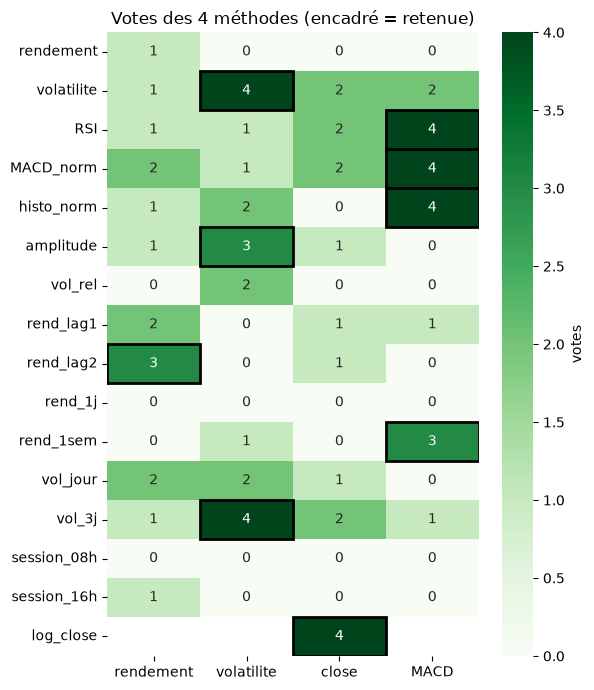

rendement   -> ['rend_lag2']
volatilite  -> ['volatilite', 'vol_3j', 'amplitude']
close       -> ['log_close']
MACD        -> ['MACD_norm', 'RSI', 'histo_norm', 'rend_1sem']


In [6]:
votes = pd.DataFrame({c: s["votes"] for c, s in scores.items()}).reindex(X_all.columns)
retenues = {c: list(s.index[s["retenue"]]) for c, s in scores.items()}

plt.figure(figsize=(6, 7))
ax = sns.heatmap(votes, annot=True, fmt=".0f", cmap="Greens", vmin=0, vmax=4, cbar_kws={"label": "votes"}, mask=votes.isna())
for j, c in enumerate(votes.columns):
    for v in retenues[c]:
        ax.add_patch(plt.Rectangle((j, list(votes.index).index(v)), 1, 1, fill=False, ec="black", lw=2))
plt.title("Votes des 4 méthodes (encadré = retenue)")
plt.tight_layout(); plt.savefig("../results/selection_votes.png", dpi=150); plt.show()
for c, v in retenues.items():
    print(f"{c:11s} -> {v}")

> **Interprétation :**
>
> Ce graphique résume les votes : plus la case est verte, plus les méthodes sont d'accord. Les cases encadrées sont les variables retenues.
> Chaque cible a ses propres variables : la volatilité dépend des variables d'agitation, le MACD des variables de tendance, et le prix seulement de lui-même.

## 6. Un modèle par cible
Pour chaque cible, deux modèles sont entraînés **avec les variables retenues** : un modèle linéaire (Lasso) et une forêt aléatoire. Le meilleur sur la validation devient **le modèle de la cible**. Il est ensuite réentraîné sur tout le train et évalué une seule fois sur le test.

Pour juger la sélection, on compare aussi avec le même modèle entraîné sur **toutes** les variables, et avec la **référence naïve**.

- `gain vs naïf` > 0 : le modèle fait mieux que la référence naïve.
- Pour le rendement, on ajoute le **taux de bon sens** : le pourcentage de bougies où le signe prédit est le bon.

In [7]:
NAIF = {"rendement": lambda X: np.zeros(len(X)), "volatilite": lambda X: X["vol_jour"].values,
        "close": lambda X: X["log_close"].values, "MACD": lambda X: X["MACD_norm"].values}

def fabrique(nom):
    if nom == "Lasso":
        return make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(5), random_state=0))
    return RandomForestRegressor(**RF)

rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
lignes, modeles, predictions = [], {}, {}
for cible in Y_all.columns:
    Xtr, ytr = X_all.loc[train], Y_all.loc[train, cible]
    Xte, yte = X_all.loc[test], Y_all.loc[test, cible]
    k = int(len(Xtr) // PAR_JOUR * (1 - VAL_FRAC)) * PAR_JOUR
    cols = retenues[cible]
    val = {nom: rmse(ytr.iloc[k:], fabrique(nom).fit(Xtr[cols].iloc[:k], ytr.iloc[:k]).predict(Xtr[cols].iloc[k:]))
           for nom in ["Lasso", "ForetAleatoire"]}
    choix = min(val, key=val.get)
    m_sel = fabrique(choix).fit(Xtr[cols], ytr)
    m_tout = fabrique(choix).fit(Xtr[candidates_pour(cible)], ytr)
    p_sel, p_tout, p_naif = m_sel.predict(Xte[cols]), m_tout.predict(Xte[candidates_pour(cible)]), NAIF[cible](Xte)
    modeles[cible], predictions[cible] = m_sel, p_sel
    r_sel, r_naif = rmse(yte, p_sel), rmse(yte, p_naif)
    ligne = {"cible": cible, "modèle choisi": choix, "nb variables": len(cols),
             "RMSE val Lasso": val["Lasso"], "RMSE val forêt": val["ForetAleatoire"],
             "RMSE test (retenues)": r_sel, "RMSE test (toutes)": rmse(yte, p_tout), "RMSE test (naïf)": r_naif,
             "gain vs naïf (%)": 100 * (1 - r_sel / r_naif)}
    if cible == "rendement":
        ligne["taux de bon sens (%)"] = 100 * (np.sign(p_sel) == np.sign(yte)).mean()
    lignes.append(ligne)

resultats = pd.DataFrame(lignes).set_index("cible")
resultats.style.format("{:.5g}", subset=[c for c in resultats.columns if c not in ("modèle choisi", "nb variables")])

,modèle choisi,nb variables,RMSE val Lasso,RMSE val forêt,RMSE test (retenues),RMSE test (toutes),RMSE test (naïf),gain vs naïf (%),taux de bon sens (%)
cible,,,,,,,,,
rendement,Lasso,1,0.012924,0.012939,0.013604,0.013613,0.013614,0.074539,51.53
volatilite,Lasso,3,0.0081932,0.0083355,0.0073865,0.0074093,0.0093457,20.964,nan
close,Lasso,1,0.012994,0.049555,0.01378,0.013776,0.013614,-1.2191,nan
MACD,Lasso,4,0.00068739,0.0011181,0.00068258,0.00066749,0.0010953,37.68,nan


> **Interprétation :**
>
> Pour chaque cible, le **Lasso** (modèle linéaire) a été meilleur que la forêt aléatoire sur la validation. C'est donc le modèle choisi partout.
> - **Rendement :** le gain par rapport à « prédire 0 » est de **0,07 %**, c'est-à-dire nul. Le signe est bon **51,5 %** du temps, à peine mieux qu'une pièce de monnaie. **On ne sait pas prédire la direction de la prochaine bougie.**
> - **Volatilité :** **21 % d'erreur en moins** que la méthode naïve. **On sait prédire en partie l'agitation du marché.**
> - **Close :** le modèle fait un peu moins bien (−1,2 %) que « le prix de demain = le prix d'aujourd'hui ». Le prix se comporte comme une **marche aléatoire**.
> - **MACD :** **38 % d'erreur en moins**. Mais c'est en partie mécanique, car le MACD est une moyenne mobile du prix.
>
> Avec les variables retenues ou avec toutes les variables, l'erreur est presque la même : **la sélection garde l'essentiel avec beaucoup moins de variables.**

## 7. Prédictions sur le test (derniers 60 jours)
Valeur réelle et valeur prédite pour chaque cible. Pour `close`, le log du prix est reconverti en dollars.

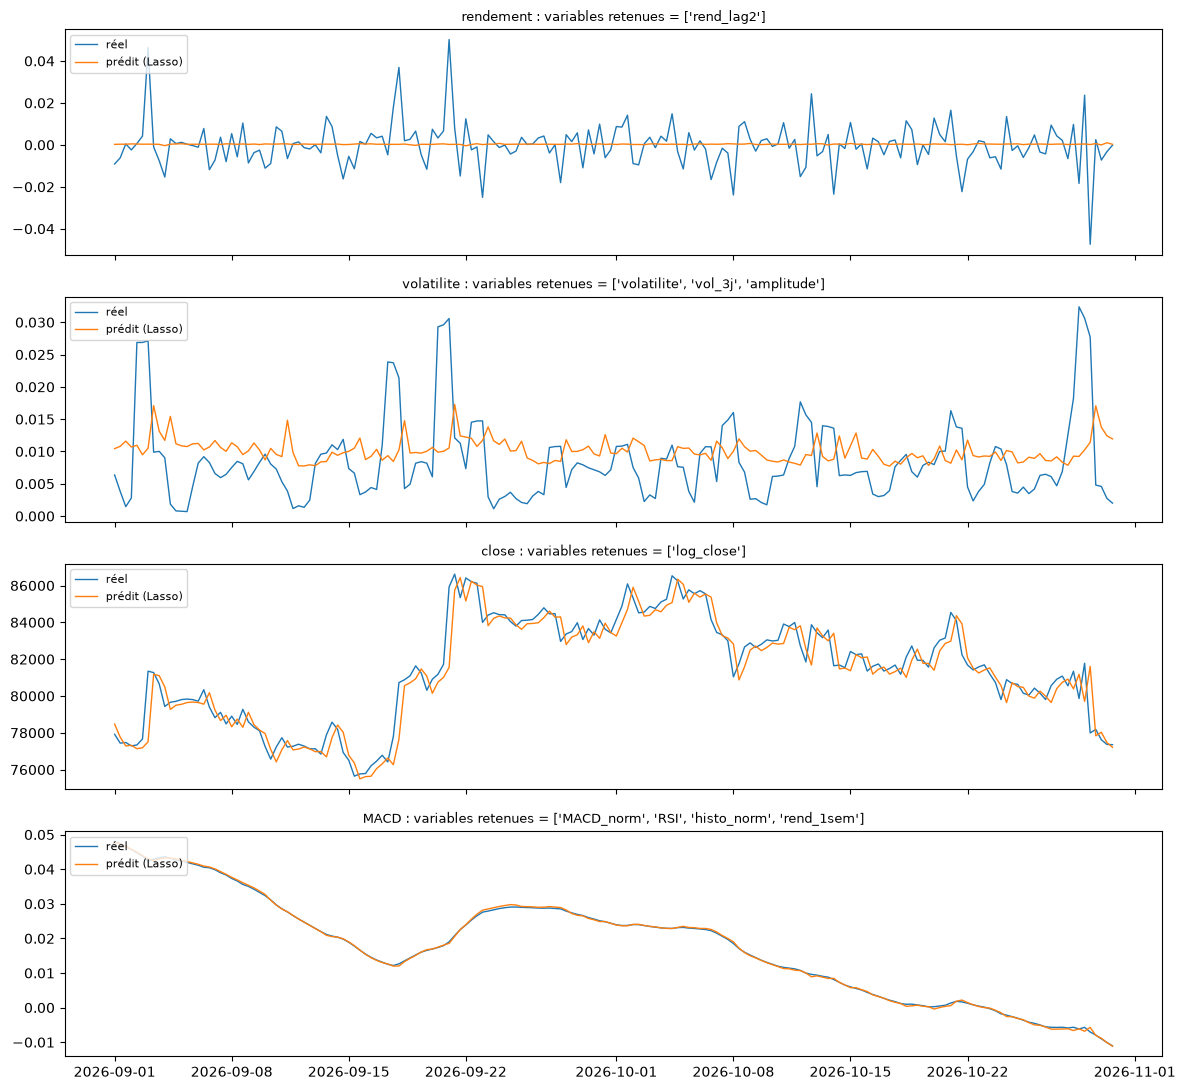

In [8]:
fin = X_all.index[test][-180:]
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, cible in zip(axes, Y_all.columns):
    reel, pred = Y_all.loc[fin, cible], pd.Series(predictions[cible], index=X_all.index[test]).loc[fin]
    if cible == "close":
        reel, pred = np.exp(reel), np.exp(pred)
    ax.plot(fin, reel, lw=1, label="réel")
    ax.plot(fin, pred, lw=1, label=f"prédit ({resultats.loc[cible, 'modèle choisi']})")
    ax.set_title(f"{cible} : variables retenues = {retenues[cible]}", fontsize=9)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("../results/selection_predictions.png", dpi=150); plt.show()

> **Interprétation :**
>
> - **Rendement :** la courbe prédite (orange) est une ligne plate proche de 0, alors que le réel (bleu) bouge dans tous les sens. Le modèle a raison de ne pas « inventer » de prévision.
> - **Volatilité :** la prédiction suit le niveau moyen mais ne voit pas venir les pics soudains. Elle monte juste après.
> - **Close :** la courbe prédite est la courbe réelle **décalée d'une bougie**. Le modèle recopie le dernier prix : c'est le signe d'une marche aléatoire.
> - **MACD :** les deux courbes se superposent presque : le MACD change lentement, il est facile à prédire.

## 8. Sauvegarde
- `results/selection_features.csv` : scores et votes de toutes les variables, pour chaque cible ;
- `results/selection_resultats.csv` : performance du modèle de chaque cible ;
- `results/features_selectionnees.json` : variables retenues par cible (réutilisées par les notebooks HMM / LSTM-HMM).

In [9]:
pd.concat(scores, names=["cible", "variable"]).to_csv("../results/selection_features.csv")
resultats.to_csv("../results/selection_resultats.csv")
with open("../results/features_selectionnees.json", "w", encoding="utf-8") as fh:
    json.dump(retenues, fh, ensure_ascii=False, indent=2)
print("Sauvegardé :", retenues)

Sauvegardé : {'rendement': ['rend_lag2'], 'volatilite': ['volatilite', 'vol_3j', 'amplitude'], 'close': ['log_close'], 'MACD': ['MACD_norm', 'RSI', 'histo_norm', 'rend_1sem']}


> **Interprétation :**
>
> Les résultats sont enregistrés dans `results/`. Le fichier `features_selectionnees.json` garde la liste des variables retenues pour chaque cible : on pourra la réutiliser dans le HMM et le LSTM-HMM.

## 9. Conclusions (période de test 2024-02 → 2026-10)

| Cible | Variables retenues | Résultat |
|---|---|---|
| **Rendement** | `rend_lag2` seulement, avec un effet très faible | Le modèle ne fait pas mieux que « prédire 0 » (gain ≈ 0 %, bon sens ≈ 51,5 %). Le rendement de la bougie suivante est **presque imprévisible** à partir des indicateurs : c'est l'efficience du marché. |
| **Volatilité** | `volatilite`, `vol_3j`, `amplitude` | **≈ 21 % d'erreur en moins** que la référence naïve. La volatilité passée et l'amplitude des bougies prédisent bien la volatilité future : ce sont les grappes de volatilité. |
| **Close** | `log_close` seulement | Le meilleur prédicteur du prix est le prix actuel : le modèle ne bat pas la référence naïve (−1 %). Le prix suit une **marche aléatoire**, c'est pourquoi on modélise les rendements et non les prix. |
| **MACD** | `MACD_norm`, `RSI`, `histo_norm`, `rend_1sem` | **≈ 38 % d'erreur en moins** que la référence naïve. Attention : le MACD est une moyenne mobile du prix, donc il se prédit en partie mécaniquement à partir de ses propres composantes. |

**Lien avec le HMM :** ce qui est prévisible dans le Bitcoin, c'est surtout la **volatilité**, et pas la direction du prix. Cela justifie un HMM dont les régimes sont portés par le couple rendement / volatilité. Les variables retenues sont sauvegardées dans `results/features_selectionnees.json` pour les notebooks HMM et LSTM-HMM.